# FIGNN Validation

This notebook evaluates the existing 29-subject LOSO outputs.

## Primary question

Does the learned representation produce an emergent workload trajectory

\[
C_0 ightarrow C_1 ightarrow C_2
\]

where the 1-back representation lies between the 0-back and 2-back representations?

### Primary criterion

`oneback_between`

This checks whether the projected 1-back position lies within the 0-back to 2-back segment.

The supporting distance-ordering criterion is:

d01 < d02

The notebook also evaluates:

- subject-level exact confidence intervals and binomial tests;
- the three subjects that satisfy the weaker distance criterion but fail the stronger trajectory criterion;
- Stage-2 calibration baselines, when their output files are available;
- frozen-model PLV-threshold sensitivity, when threshold outputs are available;
- ablation results after the training/evaluation pipeline finishes.

Procrustes is retained only as a supplementary descriptive metric.


In [1]:
from pathlib import Path
import copy, glob, json, os, pickle, re, sys

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from scipy.stats import binomtest
from statsmodels.stats.proportion import proportion_confint
from sklearn.linear_model import LinearRegression

import torch
from torch_geometric.loader import DataLoader
from torch_geometric.nn import global_mean_pool

PROJECT_ROOT = Path("/home/nvidia/24BCE1793/fignn_cni__project" )
OUTPUT_ROOT = Path("/lp-dev/24BCE1793/outputs" )
DATA_ROOT = Path("/lp-dev/24BCE1793/data" )
BASE_DIR = OUTPUT_ROOT /"evaluation_loso_all29"

FIG_DIR = (BASE_DIR /"validation_figures" )
FIG_DIR.mkdir(parents=True,exist_ok=True )

REPORT_PATH = (BASE_DIR /"loso_all29_report.json" )
SUBJECT_CSV = (BASE_DIR /"loso_all29_subject_metrics.csv" )
STAGE2_DIR = ( OUTPUT_ROOT / "stage2_calibration" )
THRESHOLD_DIR = ( OUTPUT_ROOT / "plv_threshold_sensitivity" )

ABLATION_DIR = ( OUTPUT_ROOT / "ablation_logs" )
GRAPHS_PATH = DATA_ROOT / "processed" / "all_graphs_29sub.pkl"
LOSO_ROOT = OUTPUT_ROOT / "loso"
OUTPUT_DIR = OUTPUT_ROOT / "stage2_calibration"
OUTPUT_PATH = OUTPUT_DIR / "stage2_baseline_results.csv"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_CSV=ABLATION_DIR/"ablation_detailed_results.csv"
SUMMARY_CSV=ABLATION_DIR/"ablation_summary.csv"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128
TEST_SUBJECTS = [7, 15, 22, 29]
VARIANTS = ["full", "no_plv", "no_band_weight", "node_feature_mlp", "gcn", "no_supcon", "band_power"]


sys.path.insert( 0, str(PROJECT_ROOT) )

from src.models.model import FIGNNEncoder
from ablation_train import ( NodeFeatureMLPEncoder, GCNEncoder, EmbeddingClassifier, BandPowerClassifier, make_encoder, )
from plv_threshold_sensitivity import ( THRESHOLDS, OUTPUT_DIR as THRESHOLD_OUTPUT_DIR, load_pre_graph_records, make_threshold_graphs, evaluate_threshold, )
with open(REPORT_PATH, "r") as f:
    report = json.load(f)

df = pd.read_csv(SUBJECT_CSV)
assert len(df) == 29
assert df["subject"].nunique() == 29
n = len(df)
d01_lt_d02 = df["d01_d02"] < 1.0
between = df["oneback_between"].astype(bool)
print(f"Loaded {n} LOSO subjects.")

/lp-dev/24BCE1793/fignn_env/lib/python3.13/site-packages/torch/cuda/__init__.py:64: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
/lp-dev/24BCE1793/fignn_env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Variant: full
CUDA available: True
GPU: NVIDIA A100-SXM4-80GB

Loading graphs...
Loaded 27666 graphs
After removing REST: 25056 graphs
Subjects: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
Labels: [0, 1, 2]

SUBJECT SPLIT
Train subjects: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 16, 18, 20, 21, 23, 24, 25, 26, 27, 28]
Validation subjects: [11, 17, 19, 22]
Train+validation subject pool: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28]
Train+validation subjects: 28 (must be 28 for a 29-subject LOSO fold)
Test subject: 29
Train subjects: 24 | Validation subjects: 4 | Train+validation: 28 | Test: 29
Train graphs: 20736
Validation graphs: 3456
Test graphs: 864

Computing training normalization...
Mean: [0.4861676096916199, 0.1833825558423996, 0.17238959670066833, 0.1580602377653122]
Std: [0.20799028873443604, 0.07871396839618683, 0.12091768532991409, 0.113994553685188

## 1. Primary trajectory result

The primary criterion evaluates whether the projected 1-back centroid
lies within the line segment joining the 0-back and 2-back centroids.

The supporting distance-ordering criterion is:

\[
d_{01} < d_{02}.
\]

This supporting criterion does not by itself establish that the 1-back
centroid lies between 0-back and 2-back. The segment-membership condition
is therefore treated as the primary trajectory criterion.

In [2]:
def exact_ci(k,n):
    low,high=proportion_confint(k,n,alpha=0.05,method="beta")
    return 100*low,100*high

primary_rows=[]

for label,mask in [("Supporting: d01 < d02",d01_lt_d02),("Primary: 1-back between 0B and 2B",between)]:
    k=int(mask.sum())
    low,high=exact_ci(k,n)
    primary_rows.append({"criterion":label,"successes":k,"total":n,"proportion_%":100*k/n,"95% CI":f"{low:.1f}%–{high:.1f}%","one-sided_binomial_p_vs_0.5":binomtest(k,n,p=0.5,alternative="greater").pvalue})

primary_results=pd.DataFrame(primary_rows)
display(primary_results.round(4))

,criterion,successes,total,proportion_%,95% CI,one-sided_binomial_p_vs_0.5
0,Supporting: d01 < d02,27,29,93.1034,77.2%–99.2%,0.0000
1,Primary: 1-back between 0B and 2B,23,29,79.3103,60.3%–92.0%,0.0012


In [3]:
weak_only=df.loc[d01_lt_d02 & ~between,["subject","d01","d02","d12","d01_d02","relative_1back_position","perpendicular_distance","angle_deg","path_efficiency","oneback_between"]].sort_values("subject")

print(f"{len(weak_only)} subjects satisfy d01 < d02 but fail the primary between-segment criterion.")

display(weak_only)

5 subjects satisfy d01 < d02 but fail the primary between-segment criterion.


,subject,d01,d02,d12,d01_d02,relative_1back_position,perpendicular_distance,angle_deg,path_efficiency,oneback_between
11,12,0.003386,0.024499,0.026280,0.138215,-0.065809,0.002978,124.938896,0.825811,False
13,14,0.011210,0.022212,0.024958,0.504666,-0.003911,0.011209,117.132010,0.614145,False
18,19,0.040738,0.042615,0.068359,0.955945,-0.329658,0.038239,144.185640,0.390618,False
24,25,0.029150,0.082441,0.107099,0.353589,-0.281329,0.017658,152.205720,0.605071,False
28,29,0.008228,0.042788,0.044886,0.192307,-0.031756,0.008115,109.921340,0.805574,False


### Interpretation of weak-only subjects

These subjects are not automatically errors.

They demonstrate why `d01 < d02` is insufficient by itself:

- `d01 < d02` means only that 1-back is closer to 0-back than 2-back is.
- It does not guarantee that 1-back lies within the 0-back → 2-back segment.
- The `oneback_between` criterion additionally checks the projected 1-back position along that trajectory.

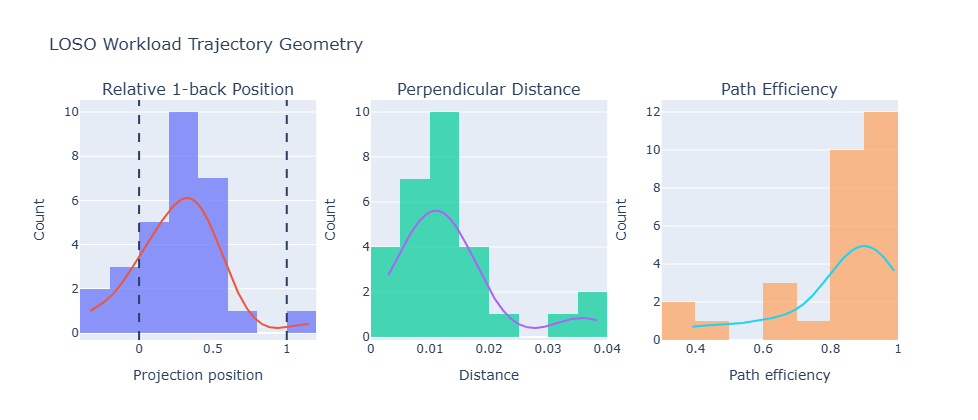

In [4]:
from scipy.stats import gaussian_kde

fig = make_subplots(rows=1,cols=3,subplot_titles=["Relative 1-back Position","Perpendicular Distance","Path Efficiency"])

for col,key in enumerate(["relative_1back_position","perpendicular_distance","path_efficiency"],1):
    x=df[key].dropna().values
    fig.add_trace(go.Histogram(x=x,nbinsx=10,opacity=0.7,showlegend=False),row=1,col=col)
    kde=gaussian_kde(x)
    xx=np.linspace(x.min(),x.max(),200)
    fig.add_trace(go.Scatter(x=xx,y=kde(xx)*len(x)*(x.max()-x.min())/10,mode="lines",showlegend=False),row=1,col=col)

fig.add_vline(x=0,line_dash="dash",row=1,col=1)
fig.add_vline(x=1,line_dash="dash",row=1,col=1)

fig.update_xaxes(title="Projection position",row=1,col=1)
fig.update_xaxes(title="Distance",row=1,col=2)
fig.update_xaxes(title="Path efficiency",row=1,col=3)
fig.update_yaxes(title="Count",row=1,col=1)
fig.update_yaxes(title="Count",row=1,col=2)
fig.update_yaxes(title="Count",row=1,col=3)

fig.update_layout(title="LOSO Workload Trajectory Geometry",height=420)
fig.show()
fig.write_html(FIG_DIR/"primary_geometry.html")

## 2. Stage-2 calibration baselines

Stage 2 evaluates frozen-encoder 64-D latent calibration for each
held-out subject using the fold-specific LOSO encoder and the
corresponding training-derived normalization statistics.

Four estimation methods are compared:

1. **Population-only** — the population 1-back centroid from the
   28 training subjects.
2. **Midpoint** — the held-out subject's REST centroid plus one-half
   of the REST-to-2-back displacement.
3. **Regression** — a population regression mapping REST and 2-back
   centroids to the corresponding 1-back centroid across the
   28 training subjects.
4. **Frozen geometric** — the held-out subject's REST-to-2-back
   trajectory using a population-derived projection coefficient.

The FIGNN encoder is not retrained or fine-tuned during Stage 2.

The true held-out 1-back centroid is used only as the evaluation target.

In [5]:
from scipy.stats import wilcoxon, ttest_rel
from stage2 import get_embeddings, get_condition_centroids, projection_position

STAGE2_OUTPUT_PATH = "/lp-dev/24BCE1793/outputs/stage2_calibration_comparison_64D.csv"
STAGE2_METHODS = ["population_only", "midpoint", "regression", "frozen_geometric"]
with open(GRAPHS_PATH,"rb") as f:
    all_graphs=pickle.load(f)

def load_stage2_fold_model(test_subject):
    checkpoint_path = os.path.join(
        LOSO_ROOT,
        f"subject_{test_subject:02d}",
        "fignn_best.pth",
    )
    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(checkpoint_path)
    model = FIGNNEncoder().to(DEVICE)
    state_dict = torch.load(checkpoint_path, map_location=DEVICE)
    if isinstance(state_dict, dict):
        if "state_dict" in state_dict:
            state_dict = state_dict["state_dict"]
        elif "model_state_dict" in state_dict:
            state_dict = state_dict["model_state_dict"]
    model.load_state_dict(state_dict)
    model.eval()
    for p in model.parameters():
        p.requires_grad = False
    return model, checkpoint_path

def load_stage2_fold_normalisation(test_subject):
    stats_path = os.path.join(
        LOSO_ROOT,
        f"subject_{test_subject:02d}",
        "normalisation_stats.pt",
    )
    if not os.path.exists(stats_path):
        raise FileNotFoundError(stats_path)
    stats = torch.load(stats_path, map_location="cpu")
    return stats["mean"].float(), stats["std"].float().clamp(min=1e-8)

def stage2_projection_position(rest, target, two_back):
    direction = two_back - rest
    denom = np.dot(direction, direction)
    if denom < 1e-12:
        return np.nan
    return float(np.dot(target - rest, direction) / denom)

def stage2_regression_prediction(train_centroids, true_rest, true_two_back):
    X = np.asarray(
        [np.concatenate([c["REST"], c["2B"]]) for c in train_centroids],
        dtype=np.float64,
    )
    Y = np.asarray(
        [c["1B"] for c in train_centroids],
        dtype=np.float64,
    )
    X_test = np.concatenate([true_rest, true_two_back]).astype(np.float64)
    X_aug = np.column_stack([np.ones(len(X)), X])
    X_test_aug = np.concatenate([[1.0], X_test])
    coef, _, _, _ = np.linalg.lstsq(X_aug, Y, rcond=None)
    return X_test_aug @ coef

stage2_results = []

for test_subject in range(1, 30):

    print("\n" + "=" * 70)
    print(f"STAGE 2 — UNSEEN SUBJECT {test_subject:02d}")
    print("=" * 70)

    train_graphs = [
        g for g in all_graphs
        if int(g.subject) != test_subject
    ]

    test_graphs = [
        g for g in all_graphs
        if int(g.subject) == test_subject
    ]

    train_subjects = sorted({
        int(g.subject) for g in train_graphs
    })

    if len(train_subjects) != 28:
        raise ValueError(
            f"Expected 28 training subjects, got {len(train_subjects)}"
        )

    mean, std = load_stage2_fold_normalisation(test_subject)

    model, checkpoint_path = load_stage2_fold_model(test_subject)

    train_subject_centroids = []

    for sid in train_subjects:

        sid_graphs = [
            g for g in train_graphs
            if int(g.subject) == sid
        ]

        z_sid, y_sid = get_embeddings(
            model=model,
            graphs=sid_graphs,
            mean=mean,
            std=std,
            device=DEVICE,
        )

        train_subject_centroids.append(
            get_condition_centroids(
                z_sid,
                y_sid,
            )
        )

    test_z, test_y = get_embeddings(
        model=model,
        graphs=test_graphs,
        mean=mean,
        std=std,
        device=DEVICE,
    )

    test_centroids = get_condition_centroids(
        test_z,
        test_y,
    )

    true_rest = test_centroids["REST"]
    true_1B = test_centroids["1B"]
    true_2B = test_centroids["2B"]

    population_prediction = np.mean(
        [c["1B"] for c in train_subject_centroids],
        axis=0,
    )

    midpoint_prediction = (
        true_rest
        + 0.5 * (true_2B - true_rest)
    )

    regression_prediction = stage2_regression_prediction(
        train_subject_centroids,
        true_rest,
        true_2B,
    )

    alpha_values = [
        stage2_projection_position(
            c["REST"],
            c["1B"],
            c["2B"],
        )
        for c in train_subject_centroids
    ]

    alpha_values = [
        a for a in alpha_values
        if np.isfinite(a)
    ]

    if not alpha_values:
        raise RuntimeError(
            f"No valid population alpha for Subject {test_subject}"
        )

    population_alpha = float(
        np.mean(alpha_values)
    )

    frozen_geometric_prediction = (
        true_rest
        + population_alpha
        * (true_2B - true_rest)
    )

    predictions = {
        "population_only": population_prediction,
        "midpoint": midpoint_prediction,
        "regression": regression_prediction,
        "frozen_geometric": frozen_geometric_prediction,
    }

    for method, prediction in predictions.items():

        prediction = np.asarray(
            prediction,
            dtype=np.float64,
        )

        error_64D = float(
            np.linalg.norm(
                prediction - true_1B
            )
        )

        prediction_alpha = (
            stage2_projection_position(
                true_rest,
                prediction,
                true_2B,
            )
            if method in {
                "midpoint",
                "frozen_geometric",
            }
            else np.nan
        )

        stage2_results.append({
            "subject": test_subject,
            "method": method,
            "error_64D": error_64D,
            "prediction_alpha": (
                float(prediction_alpha)
                if np.isfinite(prediction_alpha)
                else np.nan
            ),
            "population_alpha": (
                population_alpha
                if method == "frozen_geometric"
                else np.nan
            ),
            "prediction_norm": float(
                np.linalg.norm(prediction)
            ),
            "true_1B_norm": float(
                np.linalg.norm(true_1B)
            ),
            "rest_norm": float(
                np.linalg.norm(true_rest)
            ),
            "two_back_norm": float(
                np.linalg.norm(true_2B)
            ),
            "checkpoint": checkpoint_path,
        })

        print(
            f"{method:20s} | "
            f"64-D error = {error_64D:.6f}"
        )

stage2_df = (
    pd.DataFrame(stage2_results)
    .sort_values(
        ["subject", "method"]
    )
    .reset_index(drop=True)
)

stage2_df.to_csv(
    STAGE2_OUTPUT_PATH,
    index=False,
)

print("\n" + "=" * 70)
print("STAGE 2 — 64-D METHOD SUMMARY")
print("=" * 70)

stage2_summary = (
    stage2_df
    .groupby("method")["error_64D"]
    .agg(
        mean="mean",
        std="std",
        median="median",
        count="count",
    )
    .reindex(STAGE2_METHODS)
)

display(
    stage2_summary.round(6)
)

baseline_errors = (
    stage2_df[
        stage2_df["method"] == "population_only"
    ][
        ["subject", "error_64D"]
    ]
    .rename(
        columns={
            "error_64D":
            "population_error_64D"
        }
    )
)

stage2_comparison = stage2_df.merge(
    baseline_errors,
    on="subject",
    how="left",
)

stage2_comparison[
    "absolute_improvement"
] = (
    stage2_comparison[
        "population_error_64D"
    ]
    -
    stage2_comparison[
        "error_64D"
    ]
)

stage2_comparison[
    "percent_improvement"
] = np.where(
    stage2_comparison[
        "population_error_64D"
    ] > 1e-12,
    100.0
    * stage2_comparison[
        "absolute_improvement"
    ]
    / stage2_comparison[
        "population_error_64D"
    ],
    np.nan,
)

stage2_comparison[
    "improved_over_population"
] = (
    stage2_comparison[
        "error_64D"
    ]
    <
    stage2_comparison[
        "population_error_64D"
    ]
)

print("\n" + "=" * 70)
print("COMPARISON AGAINST POPULATION-ONLY")
print("=" * 70)

display(
    stage2_comparison[
        [
            "subject",
            "method",
            "error_64D",
            "population_error_64D",
            "absolute_improvement",
            "percent_improvement",
            "improved_over_population",
        ]
    ]
    .sort_values(
        ["subject", "method"]
    )
    .round(6)
)

paired_test_rows = []

for method in STAGE2_METHODS[1:]:

    base = (
        stage2_df[
            stage2_df["method"]
            == "population_only"
        ]
        .sort_values("subject")
    )

    current = (
        stage2_df[
            stage2_df["method"]
            == method
        ]
        .sort_values("subject")
    )

    base_error = (
        base["error_64D"]
        .to_numpy()
    )

    method_error = (
        current["error_64D"]
        .to_numpy()
    )

    wilcoxon_W, wilcoxon_p = wilcoxon(
        base_error,
        method_error,
        alternative="greater",
    )

    paired_t, paired_t_p = ttest_rel(
        base_error,
        method_error,
    )

    differences = (
        base_error
        - method_error
    )

    sd_difference = np.std(
        differences,
        ddof=1,
    )

    paired_test_rows.append({
        "method": method,
        "wilcoxon_W": float(wilcoxon_W),
        "wilcoxon_p": float(wilcoxon_p),
        "paired_t_t": float(paired_t),
        "paired_t_p": float(paired_t_p),
        "mean_error_reduction": float(
            np.mean(differences)
        ),
        "cohen_dz": (
            float(
                np.mean(differences)
                / sd_difference
            )
            if sd_difference > 1e-12
            else np.nan
        ),
        "n_improved": int(
            np.sum(
                method_error
                < base_error
            )
        ),
        "n_subjects": len(
            base_error
        ),
    })

paired_tests_df = pd.DataFrame(
    paired_test_rows
)

# Holm correction across the three Wilcoxon comparisons.
order = np.argsort(
    paired_tests_df[
        "wilcoxon_p"
    ].to_numpy()
)

adjusted = np.empty(
    len(paired_tests_df)
)

running = 0.0
m = len(paired_tests_df)

for rank, idx in enumerate(order):

    value = min(
        1.0,
        (m - rank)
        * paired_tests_df.loc[
            idx,
            "wilcoxon_p",
        ],
    )

    running = max(
        running,
        value,
    )

    adjusted[idx] = running

paired_tests_df[
    "wilcoxon_p_holm"
] = adjusted

print("\n" + "=" * 70)
print("PAIRED STATISTICAL TESTS VS POPULATION-ONLY")
print("=" * 70)

display(
    paired_tests_df.round(8)
)

paired_tests_path = (
    STAGE2_OUTPUT_PATH
    .replace(
        ".csv",
        "_paired_tests.csv",
    )
)

paired_tests_df.to_csv(
    paired_tests_path,
    index=False,
)

print(
    f"\nSaved Stage-2 results:\n"
    f"{STAGE2_OUTPUT_PATH}"
)

print(
    f"\nSaved paired tests:\n"
    f"{paired_tests_path}"
)

Loading graphs...
Loaded 27666 graphs
Using device: cuda

STAGE 2 — UNSEEN SUBJECT 01
population_only      | 64-D error = 0.054337
midpoint             | 64-D error = 0.084958
regression           | 64-D error = 0.080533
frozen_geometric     | 64-D error = 0.056798

STAGE 2 — UNSEEN SUBJECT 02
population_only      | 64-D error = 0.071156
midpoint             | 64-D error = 0.026146
regression           | 64-D error = 0.058397
frozen_geometric     | 64-D error = 0.024916

STAGE 2 — UNSEEN SUBJECT 03
population_only      | 64-D error = 0.139185
midpoint             | 64-D error = 0.065468
regression           | 64-D error = 0.134015
frozen_geometric     | 64-D error = 0.036172

STAGE 2 — UNSEEN SUBJECT 04
population_only      | 64-D error = 0.027844
midpoint             | 64-D error = 0.086676
regression           | 64-D error = 0.030765
frozen_geometric     | 64-D error = 0.042476

STAGE 2 — UNSEEN SUBJECT 05
population_only      | 64-D error = 0.051690
midpoint             | 64-D error

,mean,std,median,count
method,,,,
population_only,0.064860,0.031883,0.056985,29
midpoint,0.052229,0.025477,0.050302,29
regression,0.050297,0.030208,0.047265,29
frozen_geometric,0.034542,0.016811,0.029759,29



COMPARISON AGAINST POPULATION-ONLY


,subject,method,error_64D,population_error_64D,absolute_improvement,percent_improvement,improved_over_population
0,1,frozen_geometric,0.056798,0.054337,-0.002461,-4.528382,False
1,1,midpoint,0.084958,0.054337,-0.030621,-56.353665,False
2,1,population_only,0.054337,0.054337,0.000000,0.000000,False
3,1,regression,0.080533,0.054337,-0.026196,-48.209907,False
4,2,frozen_geometric,0.024916,0.071156,0.046240,64.983947,True
...,...,...,...,...,...,...,...
111,28,regression,0.096898,0.039064,-0.057835,-148.052471,False
112,29,frozen_geometric,0.016615,0.102053,0.085437,83.718920,True
113,29,midpoint,0.022240,0.102053,0.079813,78.207772,True
114,29,population_only,0.102053,0.102053,0.000000,0.000000,False



PAIRED STATISTICAL TESTS VS POPULATION-ONLY


,method,wilcoxon_W,wilcoxon_p,paired_t_t,paired_t_p,mean_error_reduction,cohen_dz,n_improved,n_subjects,wilcoxon_p_holm
0,midpoint,280.0,0.091417,1.682516,0.103589,0.012630,0.312435,18,29,0.091417
1,regression,330.0,0.006913,2.613235,0.014268,0.014563,0.485266,19,29,0.013826
2,frozen_geometric,377.0,0.000135,4.422610,0.000134,0.030317,0.821258,22,29,0.000404



Saved Stage-2 results:
/lp-dev/24BCE1793/outputs/stage2_calibration_comparison_64D.csv

Saved paired tests:
/lp-dev/24BCE1793/outputs/stage2_calibration_comparison_64D_paired_tests.csv


## 3. Frozen-model PLV-threshold sensitivity

This analysis evaluates the sensitivity of the learned workload geometry
to the graph-construction PLV threshold without retraining the FIGNN.

The tested thresholds are:

\[
0.3,\;0.4,\;0.5,\;0.6,\;0.7.
\]

For each threshold:

1. reconstruct the graph topology from the original four-band PLV matrices;
2. retain the corresponding node features and frequency-specific edge attributes;
3. load the already-trained fold-specific LOSO FIGNN checkpoint;
4. apply the corresponding training-derived normalization statistics;
5. encode the held-out subject and the 28 training subjects;
6. construct the training-subject population trajectory;
7. evaluate the same Stage-1 trajectory geometry.

The encoder parameters are frozen throughout this analysis. Therefore,
this experiment measures sensitivity of the downstream representation
to graph topology induced by the PLV threshold rather than sensitivity
of the trained model itself.

The primary reported quantity is the proportion of subjects for whom
the 1-back centroid lies within the 0-back to 2-back trajectory segment.
Supporting geometry includes \(d_{01}/d_{02}\), relative 1-back position,
perpendicular distance, path efficiency, and trajectory angle.

Before interpreting the threshold results, the threshold-0.5 reconstruction
must reproduce the authoritative graph representation used for the final
LOSO evaluation. This is a reproducibility sanity check, not a new
training experiment.

In [6]:
pre_graph_records = load_pre_graph_records()

print(f"Loaded {len(pre_graph_records):,} pre-graph records")
print(f"Thresholds: {THRESHOLDS}")

Loaded 25,056 pre-graph records
Thresholds: [0.3, 0.4, 0.5, 0.6, 0.7]


In [7]:
all_threshold_results = []

for threshold in THRESHOLDS:
    graphs_t = make_threshold_graphs(threshold,pre_graph_records)
    result_t = evaluate_threshold(threshold,graphs_t)
    all_threshold_results.append(result_t)
    del graphs_t
    torch.cuda.empty_cache()

threshold_results = pd.concat(all_threshold_results,ignore_index=True)
threshold_results.to_csv(THRESHOLD_OUTPUT_DIR /"threshold_results.csv",index=False)
print(f"Saved {len(threshold_results):,} rows to "f"{THRESHOLD_OUTPUT_DIR / 'threshold_results.csv'}")

Threshold 0.3: 25,056 graphs | mean undirected edges = 1348.59

THRESHOLD = 0.3

Subject 01/29
  d01/d02=0.8078 | d12/d02=1.0986 | angle=118.96° | eff=0.5245 | 1B position=0.2228 | centrality=0.4455 | perp=0.0098 | between=True

Subject 02/29
  d01/d02=0.1981 | d12/d02=0.8507 | angle=45.31° | eff=0.9535 | 1B position=0.1578 | centrality=0.3156 | perp=0.0219 | between=True

Subject 03/29
  d01/d02=0.4660 | d12/d02=1.1313 | angle=118.12° | eff=0.6261 | 1B position=-0.0313 | centrality=0.0000 | perp=0.0215 | between=False

Subject 04/29
  d01/d02=0.6544 | d12/d02=0.4256 | angle=45.46° | eff=0.9260 | 1B position=0.6235 | centrality=0.7530 | perp=0.0131 | between=True

Subject 05/29
  d01/d02=0.8643 | d12/d02=0.2900 | angle=70.32° | eff=0.8663 | 1B position=0.8315 | centrality=0.3371 | perp=0.0157 | between=True

Subject 06/29
  d01/d02=0.7358 | d12/d02=0.4195 | angle=62.75° | eff=0.8656 | 1B position=0.6827 | centrality=0.6346 | perp=0.0169 | between=True

Subject 07/29
  d01/d02=0.2429 | 

In [8]:
# ============================================================
# THRESHOLD SUMMARY
# ============================================================

summary = (
    threshold_results
    .groupby("threshold")
    .agg(
        subjects=("subject", "nunique"),
        between_count=("oneback_between_x", "sum"),
        between_rate=("oneback_between_x", "mean"),
        mean_d01_d02=("d01_d02", "mean"),
        std_d01_d02=("d01_d02", "std"),
        mean_d12_d02=("d12_d02", "mean"),
        std_d12_d02=("d12_d02", "std"),
        mean_relative_position=(
            "relative_1back_position",
            "mean",
        ),
        std_relative_position=(
            "relative_1back_position",
            "std",
        ),
        mean_perpendicular_distance=(
            "perpendicular_distance",
            "mean",
        ),
        std_perpendicular_distance=(
            "perpendicular_distance",
            "std",
        ),
        mean_path_efficiency=(
            "path_efficiency",
            "mean",
        ),
        std_path_efficiency=(
            "path_efficiency",
            "std",
        ),
        mean_angle=(
            "angle_deg",
            "mean",
        ),
        std_angle=(
            "angle_deg",
            "std",
        ),
        mean_procrustes=(
            "procrustes_similarity",
            "mean",
        ),
        std_procrustes=(
            "procrustes_similarity",
            "std",
        ),
        mean_direction_cosine=(
            "direction_cosine",
            "mean",
        ),
        std_direction_cosine=(
            "direction_cosine",
            "std",
        ),
    )
    .reset_index()
)

summary["between_rate_%"] = (
    100 * summary["between_rate"]
)

display(
    summary.round(4)
)

summary.to_csv(
    THRESHOLD_OUTPUT_DIR / "threshold_summary.csv",
    index=False,
)

,threshold,subjects,between_count,between_rate,mean_d01_d02,std_d01_d02,mean_d12_d02,std_d12_d02,mean_relative_position,std_relative_position,...,std_perpendicular_distance,mean_path_efficiency,std_path_efficiency,mean_angle,std_angle,mean_procrustes,std_procrustes,mean_direction_cosine,std_direction_cosine,between_rate_%
0,0.3,29,21,0.7241,0.6281,0.5351,0.9002,0.4810,0.3186,0.4651,...,0.0121,0.7674,0.2172,83.7855,38.0880,0.8066,0.2187,0.6994,0.4467,72.4138
1,0.4,29,23,0.7931,0.5361,0.3926,0.8654,0.3865,0.2716,0.3431,...,0.0106,0.8036,0.2052,75.4290,39.6015,0.8472,0.1939,0.7666,0.3960,79.3103
2,0.5,29,23,0.7931,0.4772,0.2695,0.8239,0.2839,0.2705,0.2906,...,0.0088,0.8192,0.1704,73.1970,39.6714,0.8775,0.1548,0.7854,0.4036,79.3103
3,0.6,29,23,0.7931,0.4783,0.2475,0.8626,0.3461,0.2140,0.3611,...,0.0059,0.8004,0.1703,78.0622,42.2572,0.8785,0.1423,0.7677,0.3822,79.3103
4,0.7,29,25,0.8621,0.5487,0.4153,0.8805,0.5496,0.2002,0.5553,...,0.0047,0.7883,0.1782,79.7641,40.0898,0.8496,0.1507,0.7454,0.3676,86.2069


## 4. Controlled ablation evaluation

The controlled ablation evaluates the following variants on held-out subjects 7, 15, 22, and 29:

- `full`
- `no_plv`
- `no_band_weight`
- `node_feature_mlp`
- `gcn`
- `no_supcon`
- `band_power`

The same subject-wise validation protocol and fold-specific normalization are used for all variants.

In [9]:
# ============================================================
# CONTROLLED 4-FOLD ABLATION EVALUATOR
# ============================================================

print("="*80)
print("LOADING DATA")
print("="*80)

with open(GRAPHS_PATH,"rb") as f:
    all_graphs=pickle.load(f)

all_graphs=[g for g in all_graphs if int(g.y.item())!=3]
print(f"Graphs after REST removal: {len(all_graphs)}")
print(f"Device: {DEVICE}")


# ============================================================
# ABLATION TRANSFORMATION
# ============================================================

def apply_ablation(graphs,variant):
    graphs=copy.deepcopy(graphs)
    if variant=="no_plv":
        for graph in graphs:
            graph.edge_attr=torch.zeros_like(graph.edge_attr)
    return graphs


# ============================================================
# NORMALIZATION
# ============================================================

def normalize_graphs(graphs,feature_mean,feature_std):
    graphs=copy.deepcopy(graphs)
    feature_mean=feature_mean.detach().cpu()
    feature_std=feature_std.detach().cpu()
    for graph in graphs:
        graph.x=(graph.x-feature_mean)/feature_std
    return graphs


# ============================================================
# LOAD CHECKPOINT
# ============================================================

def load_checkpoint(test_subject,variant):
    path=ABLATION_DIR/f"subject_{test_subject:02d}"/f"{variant}_best.pt"
    if not path.exists():
        raise FileNotFoundError(f"Checkpoint not found:\n{path}")
    checkpoint=torch.load(path,map_location=DEVICE,weights_only=False)
    return path,checkpoint


# ============================================================
# BUILD MODEL
# ============================================================

def build_model(variant,checkpoint):
    if variant=="band_power":
        model=BandPowerClassifier(n_classes=3).to(DEVICE)
        model.load_state_dict(checkpoint["model_state_dict"])
        model.eval()
        return model,"band_power"

    if variant=="no_supcon":
        encoder=make_encoder("full")
        model=EmbeddingClassifier(encoder=encoder,latent_dim=64,n_classes=3).to(DEVICE)
        model.load_state_dict(checkpoint["model_state_dict"])
        model.eval()
        return model,"classifier"

    model=make_encoder(variant).to(DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    return model,"encoder"


# ============================================================
# EXTRACT REPRESENTATIONS
# ============================================================

@torch.no_grad()
def extract_embeddings(model,model_type,graphs):
    loader=DataLoader(graphs,batch_size=BATCH_SIZE,shuffle=False,num_workers=2,pin_memory=True)
    embeddings=[]
    labels=[]
    subjects=[]

    for batch in loader:
        batch=batch.to(DEVICE)

        if model_type=="band_power":
            z=global_mean_pool(batch.x,batch.batch)
        elif model_type=="classifier":
            z=model.encoder(batch)
        else:
            z=model(batch)

        embeddings.append(z.detach().cpu())
        labels.append(batch.y.view(-1).detach().cpu())
        subjects.extend(batch.subject.detach().cpu().tolist())

    return torch.cat(embeddings,dim=0).numpy(),torch.cat(labels,dim=0).numpy(),np.asarray(subjects)


# ============================================================
# BUILD 0B / 1B / 2B CENTROIDS
# ============================================================

def build_trajectory(embeddings,labels):
    centroids=[]

    for class_id in [0,1,2]:
        mask=labels==class_id
        if not np.any(mask):
            return None
        centroids.append(embeddings[mask].mean(axis=0))

    return np.stack(centroids,axis=0)


# ============================================================
# GEOMETRY
# ============================================================

def trajectory_geometry(T):
    C0,C1,C2=T
    d01=np.linalg.norm(C1-C0)
    d12=np.linalg.norm(C2-C1)
    d02=np.linalg.norm(C2-C0)

    v1=C0-C1
    v2=C2-C1
    denom=np.linalg.norm(v1)*np.linalg.norm(v2)

    if denom<1e-12:
        angle_deg=np.nan
    else:
        cosine=np.dot(v1,v2)/denom
        cosine=np.clip(cosine,-1.0,1.0)
        angle_deg=np.degrees(np.arccos(cosine))

    path_efficiency=d02/(d01+d12) if d01+d12>1e-12 else np.nan

    return {"d01":d01,"d12":d12,"d02":d02,"d01_d02":d01/d02 if d02>1e-12 else np.nan,"d12_d02":d12/d02 if d02>1e-12 else np.nan,"angle_deg":angle_deg,"path_efficiency":path_efficiency}


# ============================================================
# 1B RELATIVE POSITION
# ============================================================

def relative_position_metrics(T):
    C0,C1,C2=T
    direction=C2-C0
    denom=np.dot(direction,direction)

    if denom<1e-12:
        return np.nan,np.nan,np.nan,False

    t=np.dot(C1-C0,direction)/denom
    projection=C0+t*direction
    perpendicular_distance=np.linalg.norm(C1-projection)
    centrality=1.0-2.0*abs(t-0.5)
    centrality=float(np.clip(centrality,0.0,1.0))
    between=0.0<=t<=1.0

    return float(t),float(perpendicular_distance),centrality,bool(between)


# ============================================================
# PROCRUSTES SIMILARITY
# ============================================================

def procrustes_similarity(A,B):
    A=A-A.mean(axis=0,keepdims=True)
    B=B-B.mean(axis=0,keepdims=True)
    norm_A=np.linalg.norm(A)
    norm_B=np.linalg.norm(B)

    if norm_A<1e-12 or norm_B<1e-12:
        return np.nan

    A=A/norm_A
    B=B/norm_B
    M=A.T@B
    U,_,Vt=np.linalg.svd(M)
    R=U@Vt
    aligned_A=A@R
    error=np.linalg.norm(aligned_A-B)

    return float(np.clip(1.0-error/np.sqrt(2.0),0.0,1.0))


# ============================================================
# DIRECTION COSINE
# ============================================================

def direction_cosine(subject_T,population_T):
    a=subject_T[2]-subject_T[0]
    b=population_T[2]-population_T[0]
    denom=np.linalg.norm(a)*np.linalg.norm(b)

    if denom<1e-12:
        return np.nan

    return float(np.dot(a,b)/denom)


# ============================================================
# EVALUATE ONE FOLD / VARIANT
# ============================================================

def evaluate_fold(test_subject,variant):
    print()
    print("="*80)
    print(f"SUBJECT {test_subject:02d} | {variant}")
    print("="*80)

    checkpoint_path,checkpoint=load_checkpoint(test_subject,variant)
    print(f"Checkpoint: {checkpoint_path}")

    saved_test_subject=int(checkpoint["test_subject"])

    if saved_test_subject!=test_subject:
        raise RuntimeError(f"Checkpoint says test subject {saved_test_subject},expected {test_subject}")

    train_subjects=set(int(x) for x in checkpoint["train_subjects"])
    val_subjects=set(int(x) for x in checkpoint["validation_subjects"])

    assert len(train_subjects)==24
    assert len(val_subjects)==4
    assert len(train_subjects)+len(val_subjects)==28
    assert test_subject not in train_subjects
    assert test_subject not in val_subjects
    assert train_subjects.isdisjoint(val_subjects)

    print(f"Train subjects      : {len(train_subjects)}")
    print(f"Validation subjects : {len(val_subjects)}")
    print(f"Held-out subject    : {test_subject}")

    feature_mean=checkpoint["feature_mean"]
    feature_std=checkpoint["feature_std"]

    train_graphs=[g for g in all_graphs if int(g.subject) in train_subjects]
    test_graphs=[g for g in all_graphs if int(g.subject)==test_subject]

    if not train_graphs:
        raise RuntimeError("No training graphs found.")

    if not test_graphs:
        raise RuntimeError("No test graphs found.")

    train_graphs=normalize_graphs(train_graphs,feature_mean,feature_std)
    test_graphs=normalize_graphs(test_graphs,feature_mean,feature_std)

    train_graphs=apply_ablation(train_graphs,variant)
    test_graphs=apply_ablation(test_graphs,variant)

    model,model_type=build_model(variant,checkpoint)

    train_z,train_y,train_sid=extract_embeddings(model,model_type,train_graphs)
    training_trajectories=[]

    for subject in sorted(train_subjects):
        mask=train_sid==subject
        T=build_trajectory(train_z[mask],train_y[mask])
        if T is not None:
            training_trajectories.append(T)

    if not training_trajectories:
        raise RuntimeError("No valid training trajectories.")

    training_trajectories=np.stack(training_trajectories,axis=0)
    population_T=training_trajectories.mean(axis=0)

    test_z,test_y,_=extract_embeddings(model,model_type,test_graphs)
    subject_T=build_trajectory(test_z,test_y)

    if subject_T is None:
        raise RuntimeError(f"Could not build complete 0B/1B/2B trajectory for subject {test_subject}")

    geometry=trajectory_geometry(subject_T)
    relative_1b,perpendicular_distance,centrality,between=relative_position_metrics(subject_T)
    proc=procrustes_similarity(subject_T,population_T)
    dir_cos=direction_cosine(subject_T,population_T)

    result={"test_subject":test_subject,"variant":variant,"train_subject_count":len(train_subjects),"validation_subject_count":len(val_subjects),
            "population_subject_count":len(training_trajectories),"best_epoch":checkpoint.get("epoch",np.nan),"best_validation_loss":checkpoint.get("validation_loss",np.nan),
            "d01":geometry["d01"],"d12":geometry["d12"],"d02":geometry["d02"],"d01_d02":geometry["d01_d02"],"d12_d02":geometry["d12_d02"],"angle_deg":geometry["angle_deg"],
            "path_efficiency":geometry["path_efficiency"],"relative_1back_position":relative_1b,"perpendicular_distance":perpendicular_distance,"centrality":centrality,
            "between":between,"procrustes_similarity":proc,"direction_cosine":dir_cos}

    print(f"d01/d02          = {result['d01_d02']:.4f}")
    print(f"relative 1B      = {result['relative_1back_position']:.4f}")
    print(f"perpendicular    = {result['perpendicular_distance']:.4f}")
    print(f"between          = {result['between']}")
    print(f"path efficiency  = {result['path_efficiency']:.4f}")
    print(f"Procrustes       = {result['procrustes_similarity']:.4f}")
    print(f"direction cosine = {result['direction_cosine']:.4f}")

    return result


# ============================================================
# RUN ALL 28
# ============================================================

print()
print("="*80)
print("RUNNING 4-FOLD ABLATION EVALUATION")
print("="*80)
print(f"Subjects : {TEST_SUBJECTS}")
print(f"Variants : {VARIANTS}")
print(f"Expected : {len(TEST_SUBJECTS)*len(VARIANTS)} evaluations")

results=[]

for subject in TEST_SUBJECTS:
    for variant in VARIANTS:
        results.append(evaluate_fold(subject,variant))


# ============================================================
# SAVE RAW RESULTS
# ============================================================

results_df=pd.DataFrame(results)
assert len(results_df)==28
results_df.to_csv(OUTPUT_CSV,index=False)


# ============================================================
# SUMMARY
# ============================================================

summary_rows=[]

for variant in VARIANTS:
    subset=results_df[results_df["variant"]==variant]
    assert len(subset)==4

    summary_rows.append({"variant":variant,"n_folds":4,"d01_d02_mean":subset["d01_d02"].mean(),"d01_d02_sd":subset["d01_d02"].std(ddof=1),"d12_d02_mean":subset["d12_d02"].mean(),
                         "d12_d02_sd":subset["d12_d02"].std(ddof=1),"angle_deg_mean":subset["angle_deg"].mean(),"angle_deg_sd":subset["angle_deg"].std(ddof=1),
                         "path_efficiency_mean":subset["path_efficiency"].mean(),"path_efficiency_sd":subset["path_efficiency"].std(ddof=1),
                         "relative_1back_position_mean":subset["relative_1back_position"].mean(), "relative_1back_position_sd":subset["relative_1back_position"].std(ddof=1),"perpendicular_distance_mean":subset["perpendicular_distance"].mean(),
                         "perpendicular_distance_sd":subset["perpendicular_distance"].std(ddof=1),"centrality_mean":subset["centrality"].mean(),"centrality_sd":subset["centrality"].std(ddof=1),"between_count":int(subset["between"].sum()),
                         "between_rate":subset["between"].mean(),"procrustes_mean":subset["procrustes_similarity"].mean(),"procrustes_sd":subset["procrustes_similarity"].std(ddof=1),"direction_cosine_mean":subset["direction_cosine"].mean(),
                         "direction_cosine_sd":subset["direction_cosine"].std(ddof=1)})

summary_df=pd.DataFrame(summary_rows)
summary_df.to_csv(SUMMARY_CSV,index=False)


# ============================================================
# PRINT RESULTS
# ============================================================

print()
print("="*110)
print("RAW 4-FOLD RESULTS")
print("="*110)

print(results_df[["test_subject","variant","d01_d02","d12_d02","angle_deg","path_efficiency","relative_1back_position","perpendicular_distance","centrality",
                  "between","procrustes_similarity","direction_cosine"]].round(4).to_string(index=False))

print()
print("="*110)
print("4-FOLD SUMMARY")
print("="*110)
print(summary_df.round(4).to_string(index=False))

print()
print("="*110)
print(f"Saved detailed results:\n{OUTPUT_CSV}")
print(f"Saved summary:\n{SUMMARY_CSV}")
print("="*110)

LOADING DATA
Graphs after REST removal: 25056
Device: cuda

RUNNING 4-FOLD ABLATION EVALUATION
Subjects : [7, 15, 22, 29]
Variants : ['full', 'no_plv', 'no_band_weight', 'node_feature_mlp', 'gcn', 'no_supcon', 'band_power']
Expected : 28 evaluations

SUBJECT 07 | full
Checkpoint: /lp-dev/24BCE1793/outputs/ablation_logs/subject_07/full_best.pt
Train subjects      : 24
Validation subjects : 4
Held-out subject    : 7
d01/d02          = 0.2103
relative 1B      = 0.1708
perpendicular    = 0.0046
between          = True
path efficiency  = 0.9537
Procrustes       = 0.9675
direction cosine = 0.8868

SUBJECT 07 | no_plv
Checkpoint: /lp-dev/24BCE1793/outputs/ablation_logs/subject_07/no_plv_best.pt
Train subjects      : 24
Validation subjects : 4
Held-out subject    : 7
d01/d02          = 0.1271
relative 1B      = 0.0758
perpendicular    = 0.0030
between          = True
path efficiency  = 0.9462
Procrustes       = 0.8855
direction cosine = 0.8922

SUBJECT 07 | no_band_weight
Checkpoint: /lp-dev/2